# Guía N.º 1: preparación y exploración de datos reales
**INFB6052 · Herramientas para Ciencia de Datos · UTEM**

**Datos A:** caudal anual del río Nilo (señal 1D); **Datos B:** foto del lanzamiento Falcon 9/DSCOVR (imagen RGB 2D).

**Alcance:** lectura, metadatos, calidad, visualización, trazabilidad y proyección para IA. No se entrenan modelos.

**Antes de empezar:** seleccionar kernel del entorno virtual `.venv` e iniciar con **Run All**. Los dos originales están incluidos en `datos/`.

In [1]:
from pathlib import Path
import sys, hashlib, platform
import importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Funciona al abrir la carpeta raíz o al ejecutar desde notebooks/.
cwd = Path.cwd().resolve()
if (cwd / 'datos').is_dir():
    RAIZ = cwd
elif (cwd.parent / 'datos').is_dir():
    RAIZ = cwd.parent
else:
    raise FileNotFoundError('Abre la carpeta raíz del proyecto en VS Code y conserva datos/.')
DIR_FIG = RAIZ / 'figuras'
DIR_FIG.mkdir(exist_ok=True)
print('Directorio del proyecto:', RAIZ)
print('Python:', sys.version.split()[0], '| Sistema:', platform.system())
print('Intérprete:', sys.executable)
for paquete in ('numpy', 'pandas', 'matplotlib', 'pillow', 'ipykernel'):
    print(f'{paquete}: {md.version(paquete)}')
print('2 + 2 =', 2 + 2)
print('Entorno virtual detectado:', Path(sys.prefix).name == '.venv')

Directorio del proyecto: C:\Users\Lolmen\Downloads\Chamba guia 1
Python: 3.14.4 | Sistema: Windows
Intérprete: c:\Users\Lolmen\Downloads\Chamba guia 1\.venv\Scripts\python.exe
numpy: 2.5.4
pandas: 3.1.0
matplotlib: 3.11.2
pillow: 13.0.0
ipykernel: 7.4.0
2 + 2 = 4
Entorno virtual detectado: True


## 1. Metadatos y fuentes de datos

**Señal:** datos *Nile River flows at Ashwan 1871–1970* distribuidos con statsmodels. Medida: volumen anual en unidades de **10⁸ m³**. La fuente declara dominio público. URL: https://www.statsmodels.org/dev/datasets/generated/nile.html. El año es un eje temporal de registros anuales, **no** se usa `t[n]=n/f_s` sin una frecuencia en Hz.

**Imagen:** `rocket.jpg`, fotografía original de SpaceX de un Falcon 9 con DSCOVR, distribuida con scikit-image; fuente documenta dominio público. URL: https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.rocket. Es una fotografía visible RGB, sin calibración radiométrica.

Fecha de consulta de las fichas: **27-10-2026**. Archivos originales conservados sin edición.

In [2]:
RUTA_SENAL = RAIZ / 'datos' / 'senal_1d' / 'nile.csv'
RUTA_IMAGEN = RAIZ / 'datos' / 'imagen_2d' / 'rocket.jpg'
assert RUTA_SENAL.is_file(), f'No existe: {RUTA_SENAL}'
assert RUTA_IMAGEN.is_file(), f'No existe: {RUTA_IMAGEN}'

def sha256_archivo(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()

print('Original CSV:', RUTA_SENAL.name, '| SHA256:', sha256_archivo(RUTA_SENAL))
print('Original JPEG:', RUTA_IMAGEN.name, '| SHA256:', sha256_archivo(RUTA_IMAGEN))

Original CSV: nile.csv | SHA256: 88e97bea7249e5832a85e41aec6ce4b8f7b1b14aae930c8363da7f193286b598
Original JPEG: rocket.jpg | SHA256: c2dd0de7c538df8d111e479619b129464d0269d0ae5fd18ca91d33a7fdfea95c


## 2. Actividad A: señal unidimensional

Se carga `nile.csv` con Pandas, se comprueba su separador y esquema y se trabaja con la columna `volume`. Se preservan todas las observaciones, sin reemplazos ni interpolación. El caudal se presenta con el año declarado por la fuente en el eje horizontal.

In [3]:
tabla_original = pd.read_csv(RUTA_SENAL, sep=',')
print('Shape tabla:', tabla_original.shape)
print('Tipos:')
print(tabla_original.dtypes)
display(tabla_original.head())

# Copia explícita de trabajo y conversión trazable
tabla = tabla_original.copy(deep=True)
valor = pd.to_numeric(tabla['volume'], errors='coerce')
anos = pd.to_numeric(tabla['year'], errors='coerce')
secuencia = valor.to_numpy(dtype=float)
mascara_finita = np.isfinite(secuencia)
no_convertibles_o_faltantes = int(valor.isna().sum())
no_finitos = int((~mascara_finita).sum())
print('Forma de la señal:', secuencia.shape, '| dtype:', secuencia.dtype)
print('Valores faltantes/no convertibles:', no_convertibles_o_faltantes)
print('Valores no finitos (NaN/Inf):', no_finitos)
print('Años faltantes o duplicados:', int(anos.isna().sum()), int(anos.duplicated().sum()))
print('Rango finito:', (float(secuencia[mascara_finita].min()), float(secuencia[mascara_finita].max())))
print('Media y mediana:', float(secuencia[mascara_finita].mean()), float(np.median(secuencia[mascara_finita])))
print('Saltos de año distintos de 1:', int((anos.diff().dropna() != 1).sum()))

Shape tabla: (100, 2)
Tipos:
year      int64
volume    int64
dtype: object


,year,volume
0,1871,1120
1,1872,1160
2,1873,963
3,1874,1210
4,1875,1160


Forma de la señal: (100,) | dtype: float64
Valores faltantes/no convertibles: 0
Valores no finitos (NaN/Inf): 0
Años faltantes o duplicados: 0 0
Rango finito: (456.0, 1370.0)
Media y mediana: 919.35 893.5
Saltos de año distintos de 1: 0


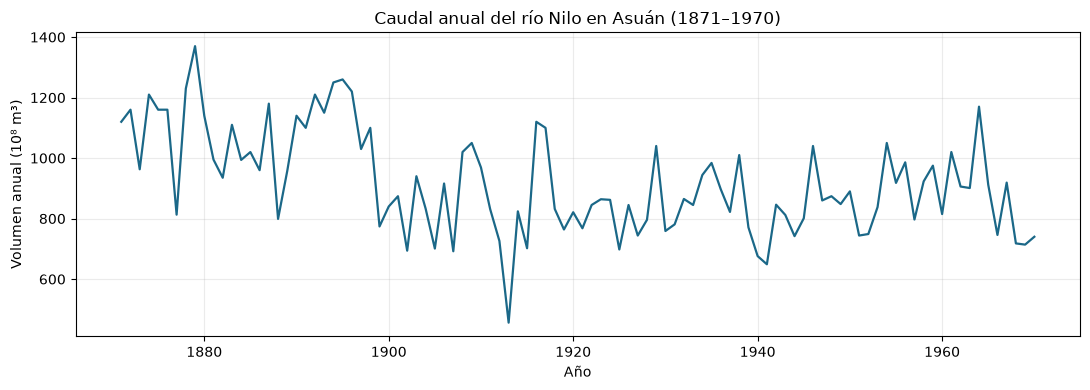

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(anos, np.where(mascara_finita, secuencia, np.nan), lw=1.6, color='#1b6888')
ax.set(title='Caudal anual del río Nilo en Asuán (1871–1970)',
       xlabel='Año', ylabel='Volumen anual (10⁸ m³)')
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(DIR_FIG / '01_senal_nilo.png', dpi=170)
plt.show()

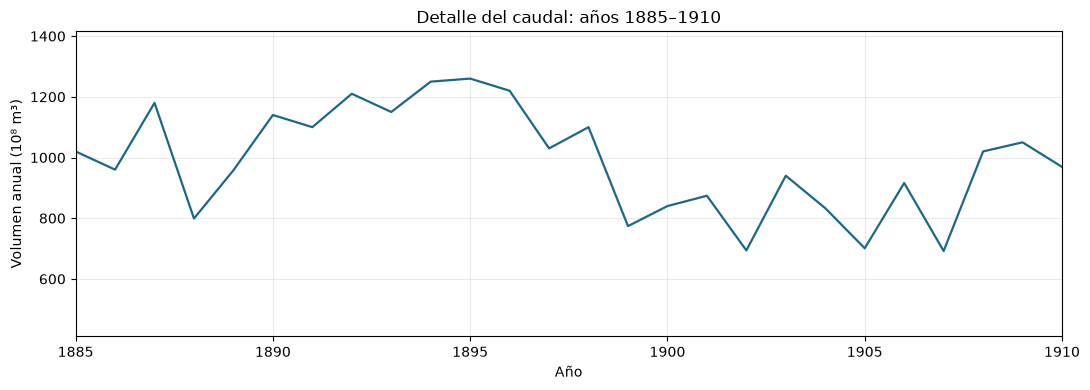

In [5]:
# Zoom de la región 1885–1910: permite observar variaciones anuales locales.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(anos, secuencia, lw=1.6, color='#1b6888')
ax.set(xlim=(1885, 1910), title='Detalle del caudal: años 1885–1910',
       xlabel='Año', ylabel='Volumen anual (10⁸ m³)')
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(DIR_FIG / '02_senal_ampliacion.png', dpi=170)
plt.show()

### Interpretación crítica de A

- La gráfica permite describir variaciones del volumen anual y años de máximos o mínimos; no establece causas físicas. La ficha del conjunto advierte un posible cambio de régimen cerca de 1898, que aquí **no se diagnostica estadísticamente**.
- No se dispone en este CSV de protocolos de calibración, errores de medición, condiciones hidráulicas completas ni variables meteorológicas adicionales.
- Eliminar un año alteraría la secuencia histórica e impediría analizar fielmente tendencias o cambios bruscos. **No se eliminó ninguna observación.**

## 3. Actividad B: imagen digital bidimensional

Se abre el archivo JPEG con Pillow, se registra el formato y se crea un arreglo NumPy sin alterar el archivo fuente. Para RGB, la matriz se expresa como **alto × ancho × 3 canales**.

Formato: JPEG | modo: RGB
Tamaño (ancho, alto): (640, 427)
Shape: (427, 640, 3) | dtype: uint8
Canales: 3
Bytes del arreglo NumPy: 819840
Rango de niveles digitales: 0 255
Proporción de valores >=250: 0.17%
Proporción de valores <=5: 0.37%
El tipo entero uint8 no puede contener NaN ni infinito.


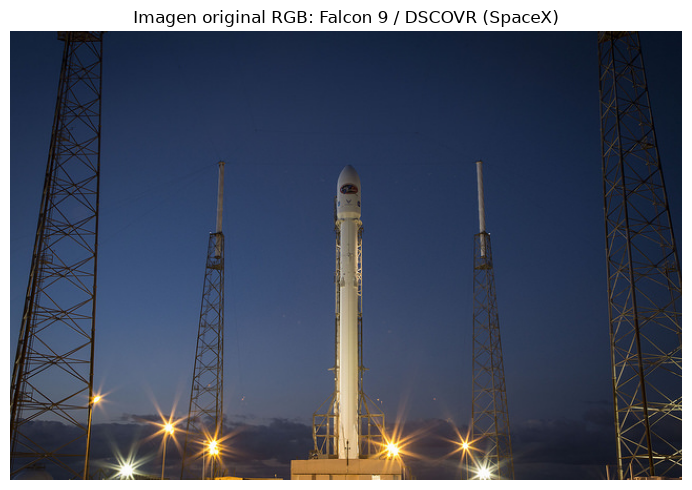

In [6]:
with Image.open(RUTA_IMAGEN) as im:
    formato = im.format
    imagen_original = im.copy()
pixeles = np.asarray(imagen_original)
print('Formato:', formato, '| modo:', imagen_original.mode)
print('Tamaño (ancho, alto):', imagen_original.size)
print('Shape:', pixeles.shape, '| dtype:', pixeles.dtype)
print('Canales:', pixeles.shape[-1] if pixeles.ndim == 3 else 1)
print('Bytes del arreglo NumPy:', pixeles.nbytes)
print('Rango de niveles digitales:', int(pixeles.min()), int(pixeles.max()))
print('Proporción de valores >=250: {:.2f}%'.format(100 * (pixeles >= 250).mean()))
print('Proporción de valores <=5: {:.2f}%'.format(100 * (pixeles <= 5).mean()))
print('El tipo entero uint8 no puede contener NaN ni infinito.')

fig, ax = plt.subplots(figsize=(9,5))
ax.imshow(imagen_original)
ax.set(title='Imagen original RGB: Falcon 9 / DSCOVR (SpaceX)')
ax.axis('off')
fig.tight_layout(); fig.savefig(DIR_FIG / '03_imagen_cohete.png', dpi=170)
plt.show()

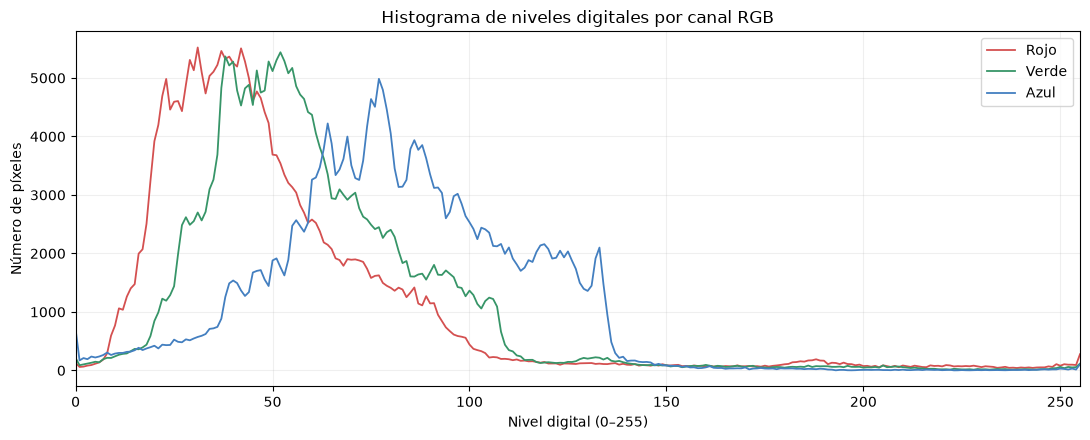

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for canal, (nombre, color) in enumerate((('Rojo','#d45050'),('Verde','#379568'),('Azul','#437fc0'))):
    hist = np.bincount(pixeles[:,:,canal].ravel(), minlength=256)
    ax.plot(np.arange(256), hist, color=color, lw=1.3, label=nombre)
ax.set(title='Histograma de niveles digitales por canal RGB',
       xlabel='Nivel digital (0–255)', ylabel='Número de píxeles', xlim=(0, 255))
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(DIR_FIG / '04_histogramas_rgb.png',dpi=170)
plt.show()

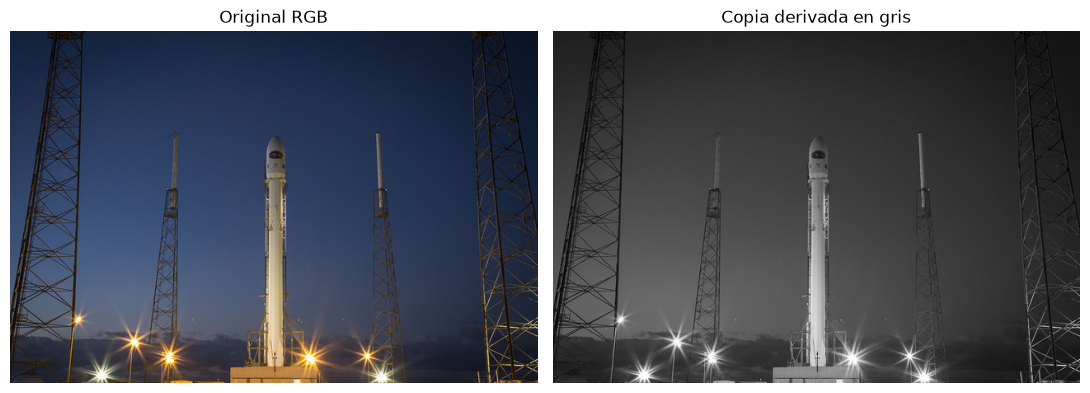

Original sigue RGB: RGB | copia: L
Hash original no alterado: c2dd0de7c538df8d111e479619b129464d0269d0ae5fd18ca91d33a7fdfea95c


In [8]:
# Transformación opcional sobre COPIA: convierte RGB a intensidad de gris.
imagen_gris_copia = imagen_original.convert('L')
gris = np.asarray(imagen_gris_copia)
fig, ax = plt.subplots(1, 2, figsize=(11,4.5))
ax[0].imshow(imagen_original); ax[0].set_title('Original RGB')
ax[1].imshow(gris, cmap='gray', vmin=0, vmax=255); ax[1].set_title('Copia derivada en gris')
for eje in ax: eje.axis('off')
fig.tight_layout(); fig.savefig(DIR_FIG / '05_comparacion_gris.png',dpi=160)
plt.show()
print('Original sigue RGB:', imagen_original.mode, '| copia:', imagen_gris_copia.mode)
print('Hash original no alterado:', sha256_archivo(RUTA_IMAGEN))

### Interpretación crítica de B

- Los canales RGB codifican valores de una fotografía de color y **no** constituyen por sí mismos mediciones físicas calibradas.
- Convertir a gris reduce la representación RGB tridimensional a una matriz de intensidades; se pierde información cromática. La conversión solo se aplicó a la copia.
- Un histograma permite observar cómo se distribuyen valores digitales; **no demuestra** fallas estructurales, temperaturas, materiales específicos ni condiciones del lanzamiento.
- El formato JPEG introduce pérdidas por compresión. Tampoco se dispone de escala física ni de datos de calibración geométrica en el archivo del ejercicio.

In [9]:
# Registro de calidad exigido: una fila por archivo.
registro = pd.DataFrame([
 {'archivo': RUTA_SENAL.name,
  'observacion': f'{len(tabla)} filas; faltantes={no_convertibles_o_faltantes}; no finitos={no_finitos}',
  'evidencia': 'Conteos NumPy/Pandas y gráfico temporal',
  'posible_impacto': 'Las oscilaciones son observables; no se explica su causa sin metadatos',
  'accion_o_justificacion': 'Se conserva toda la secuencia sin filtrar ni imputar',
  'referencia_original': sha256_archivo(RUTA_SENAL)},
 {'archivo': RUTA_IMAGEN.name,
  'observacion': f'JPEG {pixeles.shape}; tipo {pixeles.dtype}',
  'evidencia': 'Lectura de cabecera, imagen e histogramas RGB',
  'posible_impacto': 'Compresión, falta de escala y posibles extremos digitales',
  'accion_o_justificacion': 'Se conserva JPEG; gris calculado solo como copia',
  'referencia_original': sha256_archivo(RUTA_IMAGEN)}
])
display(registro)
registro.to_csv(RAIZ/'documentacion'/'registro_calidad.csv', index=False, encoding='utf-8-sig')
print('Registro de calidad guardado.')

,archivo,observacion,evidencia,posible_impacto,accion_o_justificacion,referencia_original
0,nile.csv,100 filas; faltantes=0; no finitos=0,Conteos NumPy/Pandas y gráfico temporal,Las oscilaciones son observables; no se explic...,Se conserva toda la secuencia sin filtrar ni i...,88e97bea7249e5832a85e41aec6ce4b8f7b1b14aae930c...
1,rocket.jpg,"JPEG (427, 640, 3); tipo uint8","Lectura de cabecera, imagen e histogramas RGB","Compresión, falta de escala y posibles extremo...",Se conserva JPEG; gris calculado solo como copia,c2dd0de7c538df8d111e479619b129464d0269d0ae5fd1...


Registro de calidad guardado.


## 4. Comparación integradora y posible IA (SIN entrenamiento)

| Dimensión | Señal 1D: Nilo | Imagen 2D: cohete |
|---|---|---|
| Fenómeno de ingeniería | Recursos hídricos / volumen anual | Ingeniería aeroespacial / observación visual |
| Representación / ejes | `volume` (10⁸ m³) versus `year` (años) | Imagen RGB (alto, ancho, canales) |
| Calidad observada | Conteos explícitos de nulos, finitos y continuidad anual | Dimensiones y rangos digitales; JPEG comprimido |
| Metadatos no verificados | Calibración, error de medición y variables hidrometeorológicas | Escala física, calibración y condiciones ópticas |
| Decisión tecnológica futura | Analizar riesgo hidrológico al incorporar información complementaria | Supervisión visual con cámaras calibradas y verificación experta |

**Pregunta futura de IA:** ¿puede una serie histórica de caudal, complementada con precipitación y niveles de embalses, ayudar a prever condiciones hidrológicas de riesgo? Para evaluarlo harían falta definiciones de eventos de riesgo, datos de lluvia y caudal de referencia, periodos de validación temporal separados, registros de operación hidráulica, incertidumbre y revisión de especialistas. **La fotografía del cohete no serviría como entrada para ese mismo modelo**: solo ilustra otra modalidad.

**Conclusión:** antes de aplicar IA deben verificarse procedencia, unidades, integridad, condiciones de adquisición y representatividad; ni los picos de una serie ni un histograma RGB bastan para establecer causas.

**Asistencia computacional:** se utilizó asistencia de IA para preparar el código y los documentos iniciales. Los resultados deben ser revisados y ejecutados por el estudiante en su propio equipo.